# Tutorial 1: Hydroclimatic Extreme Value Modeling (Gumbel & ETCCDI)

This tutorial demonstrates analytical Extreme Value Distribution fitting (Gumbel & GEV Type I) and calculation of standardized WMO ETCCDI precipitation indices.

**Data Provenance:**
- 45-year annual maximum daily precipitation series (1981–2025) derived from CHIRPS v3.0 DAILY_RNL (Funk et al., 2026) at 0.05°° resolution for the Upper Brantas River Basin (Malang Raya region).
- Standardized ETCCDI climate indices following WMO Expert Team guidelines (Zhang et al., 2011).


## 1. Imports and Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from inundation_risk.hydroclimate import fit_gumbel, compute_return_periods, compute_etccdi_indices

## 2. Load Rainfall Data

In [2]:
df = pd.read_csv('../benchmarks/malang_raya/data/rainfall_annual_max.csv')
print(df.head())

   year  rx1day_max_mm
0  1981           76.3
1  1982           97.1
2  1983           70.2
3  1984           81.1
4  1985          135.9


## 3. Fit Gumbel Distribution and Compute Return Periods

In [3]:
fit = fit_gumbel(df['rx1day_max_mm'], method='mle')
print('Gumbel MLE Fit Parameters:', fit)

# Compute return periods with analytical 95% Confidence Intervals (Kite/Chow delta method)
rps = compute_return_periods(fit, [2, 5, 10, 25, 50, 100], return_ci=True)
for t in [2, 5, 10, 25, 50, 100]:
    print(f"T{t} Year: {rps[f'T{t}']} mm (SE: {rps[f'T{t}_se']} mm, 95% CI: [{rps[f'T{t}_ci_lower']}, {rps[f'T{t}_ci_upper']}])")


Gumbel MLE Fit Parameters: {'loc': 82.05654309559058, 'scale': 18.888605139790673, 'sample_mean': 92.95555555555553, 'sample_std': 23.594448071484525, 'ks_stat': 0.08653931054833741, 'ks_p_value': 0.8601507138956366, 'n_samples': 45}
T2 Year: 88.98 mm (SE: 3.39 mm, 95% CI: [82.34, 95.62])
T5 Year: 110.39 mm (SE: 5.88 mm, 95% CI: [98.86, 121.92])
T10 Year: 124.56 mm (SE: 7.89 mm, 95% CI: [109.1, 140.03])
T25 Year: 142.47 mm (SE: 10.55 mm, 95% CI: [121.8, 163.14])
T50 Year: 155.76 mm (SE: 12.56 mm, 95% CI: [131.15, 180.37])
T100 Year: 168.95 mm (SE: 14.57 mm, 95% CI: [140.39, 197.51])


## 4. Plot Return Period Curve

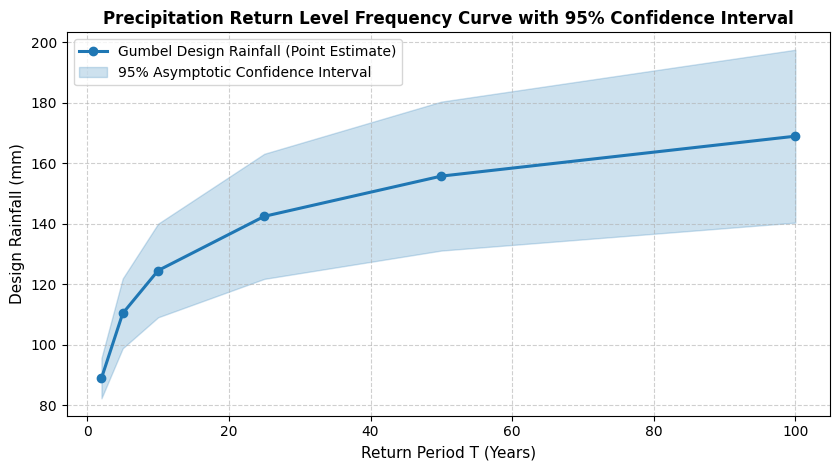

In [4]:
T_vals = [2, 5, 10, 25, 50, 100]
rain_vals = [rps[f'T{t}'] for t in T_vals]
ci_lower = [rps[f'T{t}_ci_lower'] for t in T_vals]
ci_upper = [rps[f'T{t}_ci_upper'] for t in T_vals]

plt.figure(figsize=(8.5, 4.8))
plt.plot(T_vals, rain_vals, 'o-', color='#1f77b4', linewidth=2.2, label='Gumbel Design Rainfall (Point Estimate)')
plt.fill_between(T_vals, ci_lower, ci_upper, color='#1f77b4', alpha=0.22, label='95% Asymptotic Confidence Interval')
plt.xlabel('Return Period T (Years)', fontsize=11)
plt.ylabel('Design Rainfall (mm)', fontsize=11)
plt.title('Precipitation Return Level Frequency Curve with 95% Confidence Interval', fontsize=12, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()
